# Week 4 · Notebook 2 - Spaced repetition as an RL problem

| RL piece | Re-Mind |
|---|---|
| episode | one concept, from the day it's learned to the exam (day 60) |
| state | (correct-in-a-row streak 0-5, last grade forgot/hard/easy) → 18 states |
| action | wait 1, 2, 4, 7, 14 or 30 days |
| reward | days of memory you *proved*, minus effort (below) |
| environment | the simulated student from Notebook 1 |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # so we can import the remind package
import random
import matplotlib.pyplot as plt
from remind.env import SpacedRepetitionEnv, GAPS, N_STATES, N_ACTIONS, state_id, reward
from remind.rl.qlearning import QLearningAgent, train
from remind.schedulers import evaluate, leitner, fixed, from_agent

## 1. The reward
$$r = \begin{cases} +\text{gap} - c & \text{if recalled} \\ -2\cdot\text{gap} - c & \text{if forgot}\end{cases}$$
*If you waited 14 days and still remembered, you proved 14 days of memory.* Forgetting costs double, and every review costs effort $c=1$.

In [2]:
for gap in [1, 7, 30]:
    print(gap, 'days:', 'recalled ->', reward('proven_days', gap, 2), '| forgot ->', reward('proven_days', gap, 0))

1 days: recalled -> 0.0 | forgot -> -3.0
7 days: recalled -> 6.0 | forgot -> -15.0
30 days: recalled -> 29.0 | forgot -> -61.0


## 2. Train on 40 000 simulated students (~5 s)

In [3]:
env = SpacedRepetitionEnv(seed=1)
agent = QLearningAgent(N_STATES, N_ACTIONS, alpha=0.1, gamma=0.95, epsilon_decay=0.9998, seed=1)
returns = train(env, agent, episodes=40000, log_every=5000)

episode   5000  avg return  -22.28  epsilon 0.368


episode  10000  avg return   11.74  epsilon 0.135


episode  15000  avg return   26.47  epsilon 0.050


episode  20000  avg return   30.66  epsilon 0.050


episode  25000  avg return   31.20  epsilon 0.050


episode  30000  avg return   30.77  epsilon 0.050


episode  35000  avg return   31.73  epsilon 0.050


episode  40000  avg return   32.11  epsilon 0.050


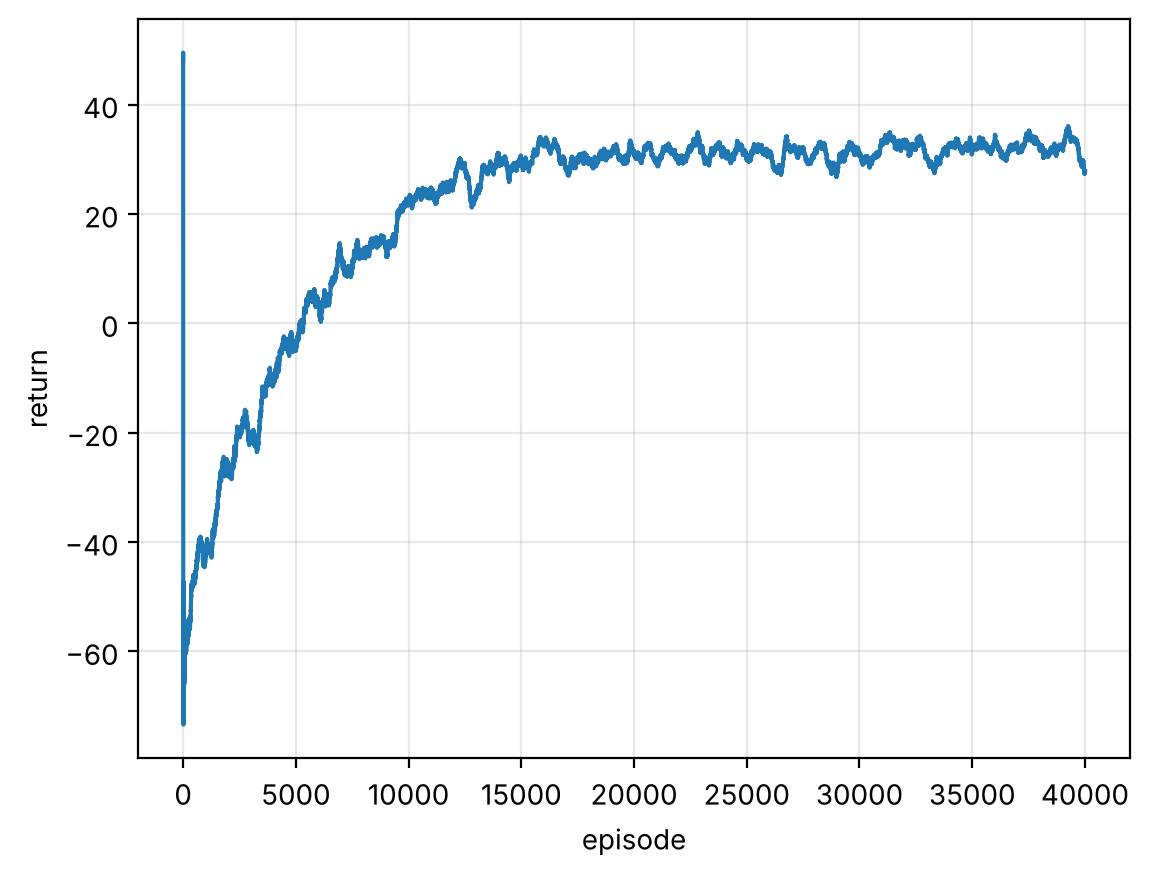

In [4]:
k = 500
plt.plot([sum(returns[max(0,i-k):i+1]) / len(returns[max(0,i-k):i+1]) for i in range(len(returns))])
plt.xlabel('episode'); plt.ylabel('return'); plt.grid(alpha=.3); plt.show()

## 3. What did the agent learn?

In [5]:
names = ['forgot', 'hard', 'easy']
print('streak  ' + '  '.join(f'{n:>6}' for n in names))
for streak in range(6):
    row = []
    for g in range(3):
        valid = (streak == 0 and g == 0) or (streak > 0 and g > 0)
        row.append(f'{GAPS[agent.act(state_id(streak, g), greedy=True)]:>6}' if valid else f"{'-':>6}")
    print(f'{streak:>6}  ' + '  '.join(row))

streak  forgot    hard    easy
     0       1       -       -
     1       -       1       1
     2       -       1       1
     3       -       4       1
     4       -       1       4
     5       -       4      14


Typical result: **review very often at first, then jump to long gaps once the memory is stable** - but not the same ladder as Leitner. Some cells look noisy: rarely visited states get few updates. Discuss!

## 4. Rules vs RL

every 2 days  reviews  30.0  retention 97.0%  exam 98.8%
every 4 days  reviews  15.0  retention 83.3%  exam 81.8%
Leitner       reviews  10.0  retention 93.3%  exam 95.3%
RL agent      reviews  11.8  retention 96.8%  exam 98.4%


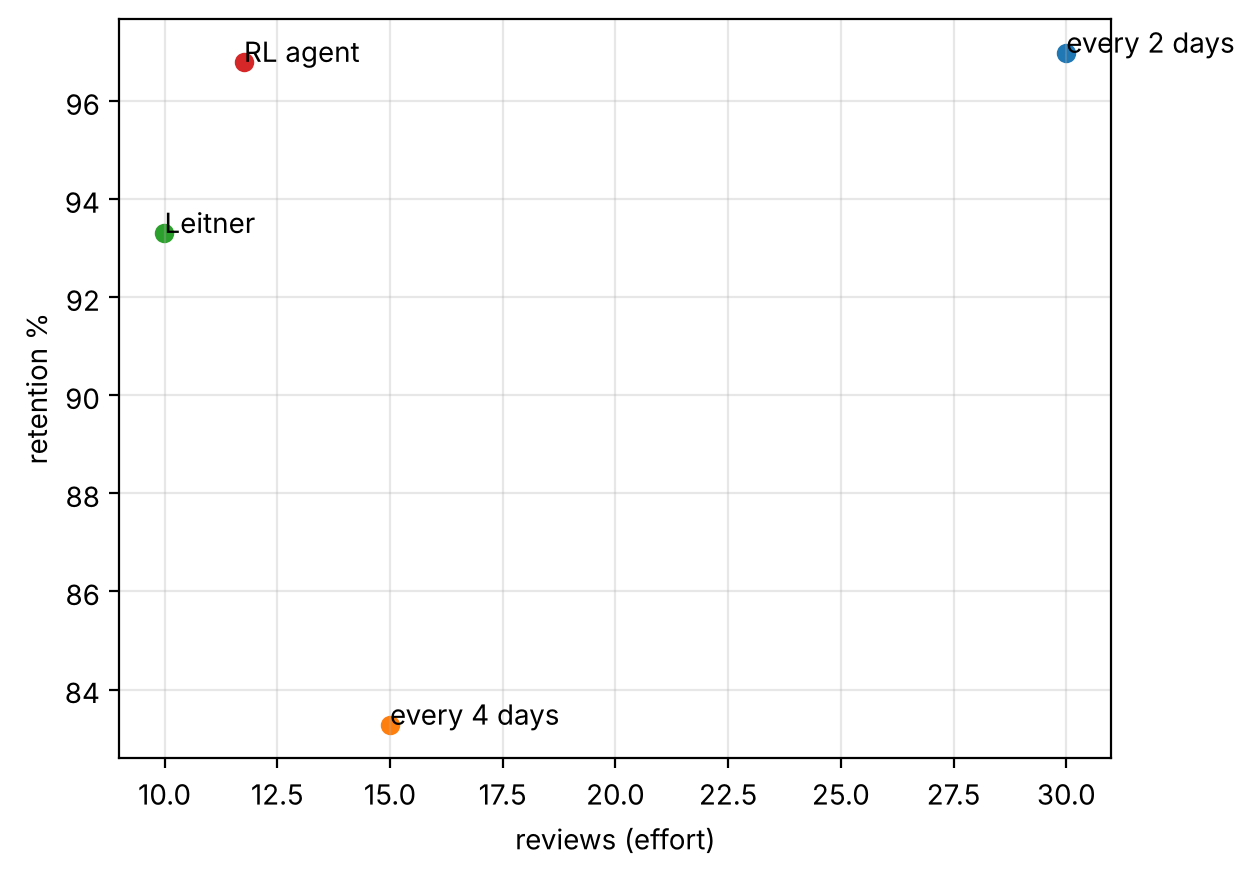

In [6]:
make_env = lambda seed: SpacedRepetitionEnv(seed=seed)
results = {name: evaluate(pol, make_env) for name, pol in [
    ('every 2 days', fixed(2)), ('every 4 days', fixed(4)), ('Leitner', leitner), ('RL agent', from_agent(agent))]}
for k, m in results.items():
    print(f"{k:13s} reviews {m['reviews']:5.1f}  retention {m['retention']:.1%}  exam {m['exam_pass']:.1%}")
for k, m in results.items():
    plt.scatter(m['reviews'], 100 * m['retention']); plt.annotate(k, (m['reviews'], 100 * m['retention']))
plt.xlabel('reviews (effort)'); plt.ylabel('retention %'); plt.grid(alpha=.3); plt.show()

## 5. Reward hacking: when the agent 'cheats'
RL optimises **exactly** what you reward - not what you meant. Try two tempting but bad rewards:

In [7]:
for mode in ['correct_count', 'long_gaps']:
    e = SpacedRepetitionEnv(seed=1, reward_mode=mode)
    a = QLearningAgent(N_STATES, N_ACTIONS, epsilon_decay=0.9998, seed=1)
    train(e, a, 40000)
    m = evaluate(from_agent(a), make_env)
    print(f"{mode:14s} reviews {m['reviews']:5.1f}  retention {m['retention']:.1%}")

correct_count  reviews  52.5  retention 97.2%


long_gaps      reviews   2.1  retention 21.7%


* **+1 per correct answer** → the agent quizzes you almost **every day**: easy points, huge workload.
* **+gap length** → it **never quizzes**, and you forget everything.

## ✍️ Exercises (part of the Week 4 assignment)
1. Change `review_cost` (try 0, 3, 6): how do the policy and the number of reviews change?
2. Add a *difficulty bucket* (from the first grade) to the state. Does RL improve? Remember to update `N_STATES`.
3. Train with 5 different seeds. Is the learned policy stable? Report mean ± std of retention.
4. Invent a third hackable reward and show the agent exploiting it.